<a href="https://colab.research.google.com/github/sravyam230/ba-booking-prediction/blob/main/Forage_BA_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Forage Job Simulations : British Airways

**Explore and prepare the dataset**

First, spend some time exploring the dataset in the “Getting Started” Jupyter Notebook provided in the Resources section below to understand the different columns and some basic statistics of the dataset. Then, you should consider how to prepare the dataset for a predictive model. You should think about any new features you want to create in order to make your model even better. You can make use of the resources provided to get you started with this task.


**Train a machine learning model**

When your data is ready for modelling, you should train a machine learning model to be able to predict the target outcome, which is a customer making a booking. For this task, you should use an algorithm that easily allows you to output information about how each variable within the model contributes to its predictive power. For example, a RandomForest is very good for this purpose.


**Evaluate the model and present findings**

After training your model, you should evaluate how well it performed by conducting cross-validation and outputting appropriate evaluation metrics. Furthermore, you should create a visualisation to interpret how each variable contributed to the model. Finally, you should summarise your findings in a single slide to be sent to your manager. Use the “PowerPoint Template” provided in the Resources section below to create your summary and make use of the links provided to help with this task.

It is recommended that the analysis portion of this task be done in Python.

# Outline

1.   Explore and prepare the dataset (Python)
        * Load and inspect the booking data
        * Clean missing values
        * Encode categorical variables
        * Engineer useful features
2.   Load and inspect the booking data
        * Build a Random Forest (or similar)
        * Predict whether a customer makes a booking
        * Output feature importance
3. Evaluate the model
        *   Cross-validation
        *   Accuracy, precision, recall, ROC-AUC
        *   Interpretation of results
4.   Create the PowerPoint summary
        *   Slide-by-slide content (ready to paste)
        *   Business-focused interpretation
        *   Graphs to include



# 1. Explore and prepare the dataset (Python)


In [ ]:
# ================================
# Task 1 — Explore & Prepare Dataset
# For Google Colab
# ================================

import pandas as pd
import numpy as np

# Optional: nicer displays
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

# ----------------
# 1) Load dataset
# ----------------
# In Colab: upload customer_booking.csv via the left sidebar (Files) or:
# from google.colab import files
# uploaded = files.upload()

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/customer_booking.csv", encoding='latin-1')  # adjust path if needed
print("Shape:", df.shape)
display(df.head())

# ----------------------------
# 2) Quick overview & checks
# ----------------------------
print("\n--- Info ---")
df.info()

print("\n--- Missing values (count) ---")
missing_counts = df.isna().sum().sort_values(ascending=False)
print(missing_counts[missing_counts > 0])

print("\n--- Target distribution (booking_complete) ---")
if "booking_complete" in df.columns:
    print(df["booking_complete"].value_counts(dropna=False))
    print(df["booking_complete"].value_counts(normalize=True, dropna=False).round(4))

print("\n--- Duplicate rows ---")
print("Duplicates:", df.duplicated().sum())

# ------------------------------------------
# 3) Basic EDA: numeric & categorical summary
# ------------------------------------------
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("\nNumeric columns:", num_cols)
print("Categorical columns:", cat_cols)

print("\n--- Numeric describe ---")
display(df[num_cols].describe().T)

print("\n--- Top values per categorical column ---")
for c in cat_cols:
    print(f"\n{c} (unique={df[c].nunique(dropna=True)})")
    display(df[c].value_counts(dropna=False).head(10))

# ---------------------------------------------------
# 4) Minimal cleaning: fix types + handle duplicates
# ---------------------------------------------------
# Drop exact duplicates (safe)
df = df.drop_duplicates().reset_index(drop=True)

# If there are date columns stored as strings, convert them
# (Uncomment/adjust if your dataset has date-like columns)
# for col in ["flight_date", "booking_date"]:
#     if col in df.columns:
#         df[col] = pd.to_datetime(df[col], errors="coerce")

# -----------------------------------------
# 5) Feature engineering (generic & safe)
# -----------------------------------------
df_fe = df.copy()

# Example: create interaction-style features if present
# (These are common in airline booking datasets, but guarded with if-checks)

if "flight_duration" in df_fe.columns and "length_of_stay" in df_fe.columns:
    df_fe["duration_x_stay"] = df_fe["flight_duration"] * df_fe["length_of_stay"]

if "wants_extra_baggage" in df_fe.columns and "wants_preferred_seat" in df_fe.columns:
    df_fe["wants_both_baggage_and_seat"] = (
        (df_fe["wants_extra_baggage"] == 1) & (df_fe["wants_preferred_seat"] == 1)
    ).astype(int)

# Optional: cap extreme outliers for numeric columns (simple winsorization)
# Uncomment if needed
# for c in num_cols:
#     lo, hi = df_fe[c].quantile([0.01, 0.99])
#     df_fe[c] = df_fe[c].clip(lo, hi)

# -------------------------------------------------------
# 6) Prepare X / y and preprocessing pipeline components
# -------------------------------------------------------
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

TARGET = "booking_complete"  # change if your target column name differs

if TARGET not in df_fe.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Columns are: {df_fe.columns.tolist()}")

X = df_fe.drop(columns=[TARGET])
y = df_fe[TARGET].astype(int)

# Recompute column lists after feature engineering
num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("\nPrepared features:")
print("Numeric:", num_features)
print("Categorical:", cat_features)
print("X shape:", X.shape, "| y shape:", y.shape)

# Numeric preprocessing: median impute
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing: most_frequent impute + one-hot
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_features),
        ("cat", categorical_transformer, cat_features),
    ],
    remainder="drop"
)

# -----------------------------------
# 7) Train/test split (for later tasks)
# -----------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)

# ---------------------------------------------
# 8) Fit preprocessor and output prepared arrays
# ---------------------------------------------
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("\nPrepared matrices:")
print("X_train_prepared:", X_train_prepared.shape)
print("X_test_prepared :", X_test_prepared.shape)

# Get final feature names (useful for later feature importance)
ohe = preprocessor.named_transformers_["cat"].named_steps["onehot"]
cat_ohe_names = ohe.get_feature_names_out(cat_features) if len(cat_features) else np.array([])

feature_names = np.concatenate([np.array(num_features), cat_ohe_names])

print("\nTotal final features:", len(feature_names))
print("First 25 feature names:", feature_names[:25])

# -----------------------------------
# 9) Save prepared datasets (optional)
# -----------------------------------
# Save the cleaned + feature engineered raw table
df_fe.to_csv("customer_booking_cleaned_feature_engineered.csv", index=False)

# Save the prepared matrices as numpy for fast reuse
np.save("X_train_prepared.npy", X_train_prepared)
np.save("X_test_prepared.npy", X_test_prepared)
np.save("y_train.npy", y_train.to_numpy())
np.save("y_test.npy", y_test.to_numpy())

# Save feature names for later interpretation
pd.Series(feature_names).to_csv("prepared_feature_names.csv", index=False, header=["feature"])

print("\nSaved files:")
print("- customer_booking_cleaned_feature_engineered.csv")
print("- X_train_prepared.npy, X_test_prepared.npy, y_train.npy, y_test.npy")
print("- prepared_feature_names.csv")


Shape: (50000, 14)


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0



--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memor

,count,mean,std,min,25%,50%,75%,max
num_passengers,50000.0,1.591240,1.020165,1.00,1.00,1.00,2.00,9.0
purchase_lead,50000.0,84.940480,90.451378,0.00,21.00,51.00,115.00,867.0
length_of_stay,50000.0,23.044560,33.887670,0.00,5.00,17.00,28.00,778.0
flight_hour,50000.0,9.066340,5.412660,0.00,5.00,9.00,13.00,23.0
wants_extra_baggage,50000.0,0.668780,0.470657,0.00,0.00,1.00,1.00,1.0
wants_preferred_seat,50000.0,0.296960,0.456923,0.00,0.00,0.00,1.00,1.0
wants_in_flight_meals,50000.0,0.427140,0.494668,0.00,0.00,0.00,1.00,1.0
flight_duration,50000.0,7.277561,1.496863,4.67,5.62,7.57,8.83,9.5
booking_complete,50000.0,0.149560,0.356643,0.00,0.00,0.00,0.00,1.0



--- Top values per categorical column ---

sales_channel (unique=2)


,count
sales_channel,
Internet,44382
Mobile,5618


... (5 outputs left out)

,count
route,
AKLKUL,2680
PENTPE,924
MELSGN,842
ICNSIN,801
DMKKIX,744
ICNSYD,695
DMKPER,679
DPSICN,666
DMKOOL,655



booking_origin (unique=104)


,count
booking_origin,
Australia,17872
Malaysia,7174
South Korea,4559
Japan,3885
China,3387
Indonesia,2369
Taiwan,2077
Thailand,2030
India,1270



Prepared features:
Numeric: ['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour', 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration', 'duration_x_stay', 'wants_both_baggage_and_seat']
Categorical: ['sales_channel', 'trip_type', 'flight_day', 'route', 'booking_origin']
X shape: (49281, 15) | y shape: (49281,)
Train: (39424, 15) Test: (9857, 15)

Prepared matrices:
X_train_prepared: (39424, 903)
X_test_prepared : (9857, 903)

Total final features: 903
First 25 feature names: ['num_passengers' 'purchase_lead' 'length_of_stay' 'flight_hour'
 'wants_extra_baggage' 'wants_preferred_seat' 'wants_in_flight_meals'
 'flight_duration' 'duration_x_stay' 'wants_both_baggage_and_seat'
 'sales_channel_Internet' 'sales_channel_Mobile' 'trip_type_CircleTrip'
 'trip_type_OneWay' 'trip_type_RoundTrip' 'flight_day_Fri'
 'flight_day_Mon' 'flight_day_Sat' 'flight_day_Sun' 'flight_day_Thu'
 'flight_day_Tue' 'flight_day_Wed' 'route_AKLDEL' 'route_AKLHGH'


# 2. Load and inspect the booking data

Numeric features: ['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour', 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration']
Categorical features: ['sales_channel', 'trip_type', 'flight_day', 'route', 'booking_origin']

--- Cross-validation (train split only) ---
accuracy : mean=0.8485  std=0.0019
precision: mean=0.4789  std=0.0285
recall   : mean=0.1045  std=0.0063
f1       : mean=0.1714  std=0.0085
roc_auc  : mean=0.7809  std=0.0024

--- Test set performance ---
Accuracy : 0.8476
Precision: 0.4645
Recall   : 0.1062
F1       : 0.1729
ROC-AUC  : 0.7732

Confusion matrix:
[[8198  181]
 [1321  157]]

Classification report:
              precision    recall  f1-score   support

           0     0.8612    0.9784    0.9161      8379
           1     0.4645    0.1062    0.1729      1478

    accuracy                         0.8476      9857
   macro avg     0.6629    0.5423    0.5445      9857
weighted avg     0.8017    0.8476    0.8046   

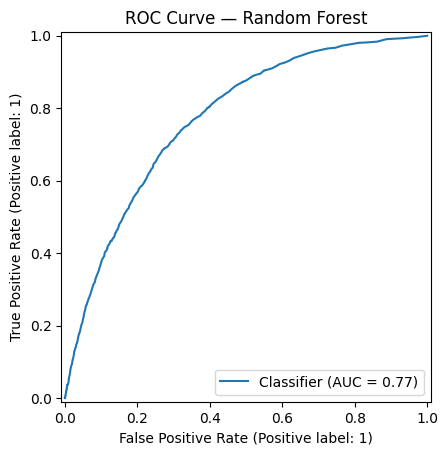


Top 25 features by importance:


,feature,importance
0,purchase_lead,0.120164
1,length_of_stay,0.100904
2,flight_hour,0.098403
3,booking_origin_Australia,0.050558
4,flight_duration,0.043885
5,num_passengers,0.039335
6,booking_origin_Malaysia,0.036538
7,wants_in_flight_meals,0.019943
8,wants_extra_baggage,0.017665
9,wants_preferred_seat,0.016139


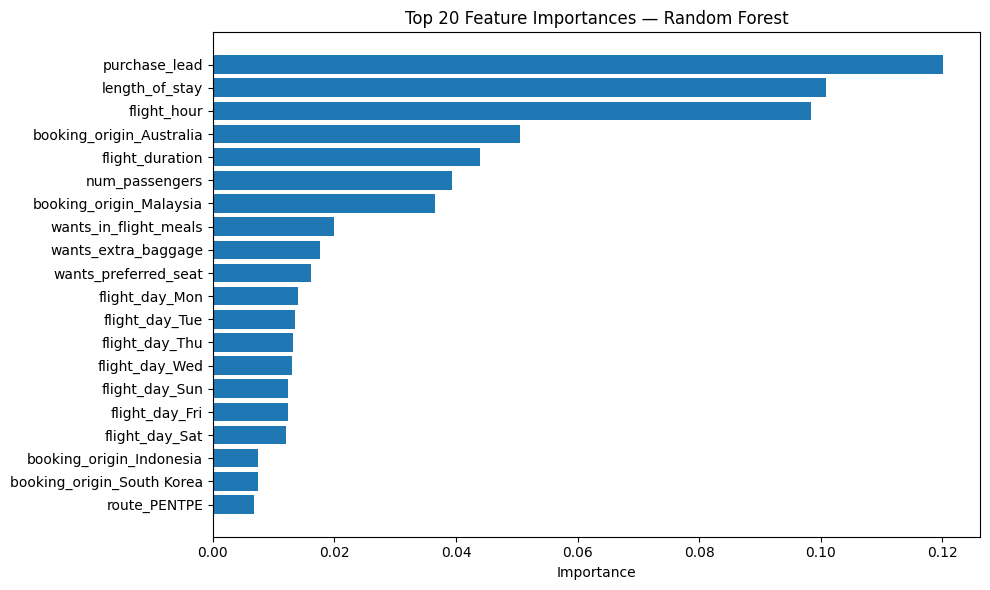


Saved:
- feature_importances.csv
- rf_booking_model.joblib


In [ ]:
#   ================================
# Task 2 — Train a model (Random Forest) + evaluate
# For Google Colab
# ================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)
from sklearn.ensemble import RandomForestClassifier

import matplotlib.pyplot as plt

# ----------------
# 1) Load dataset
# ----------------
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/customer_booking.csv", encoding='latin-1')  # adjust path if needed
df = df.drop_duplicates().reset_index(drop=True)

TARGET = "booking_complete"  # change if your target differs
if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Columns: {df.columns.tolist()}")

X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

# -----------------------------
# 2) Identify feature types
# -----------------------------
num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numeric features:", num_features)
print("Categorical features:", cat_features)

# -----------------------------------------
# 3) Preprocessing (impute + one-hot)
# -----------------------------------------
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_features),
        ("cat", categorical_transformer, cat_features),
    ],
    remainder="drop",
)

# -----------------------------------------
# 4) Model (tweakable parameters)
# -----------------------------------------
rf = RandomForestClassifier(
    n_estimators=400,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced",   # helps if classes are imbalanced
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1
)

model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("rf", rf)
])

# -----------------------------
# 5) Train/test split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# -----------------------------
# 6) Cross-validation (CV)
# -----------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    model,
    X_train, y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

print("\n--- Cross-validation (train split only) ---")
for metric in scoring.keys():
    scores = cv_results[f"test_{metric}"]
    print(f"{metric:9s}: mean={scores.mean():.4f}  std={scores.std():.4f}")

# -----------------------------
# 7) Fit on full train split
# -----------------------------
model.fit(X_train, y_train)

# -----------------------------
# 8) Evaluate on held-out test split
# -----------------------------
y_pred = model.predict(X_test)

# Some models expose predict_proba; RF does
y_proba = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_proba)

print("\n--- Test set performance ---")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1       : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=4))

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC Curve — Random Forest")
plt.show()

# -----------------------------------------
# 9) Feature importance (interpretable output)
# -----------------------------------------
# Get feature names after preprocessing
pre = model.named_steps["preprocess"]
rf_fitted = model.named_steps["rf"]

# numeric names
num_names = np.array(num_features)

# one-hot names
if len(cat_features) > 0:
    ohe = pre.named_transformers_["cat"].named_steps["onehot"]
    cat_names = ohe.get_feature_names_out(cat_features)
else:
    cat_names = np.array([])

feature_names = np.concatenate([num_names, cat_names])

importances = rf_fitted.feature_importances_
fi = pd.DataFrame({"feature": feature_names, "importance": importances})
fi = fi.sort_values("importance", ascending=False).reset_index(drop=True)

print("\nTop 25 features by importance:")
display(fi.head(25))

# Optional: plot top 20 (no custom colors)
top_n = 20
plt.figure(figsize=(10, 6))
plt.barh(fi.loc[:top_n-1, "feature"][::-1], fi.loc[:top_n-1, "importance"][::-1])
plt.title(f"Top {top_n} Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# -----------------------------------------
# 10) Save artifacts (optional)
# -----------------------------------------
fi.to_csv("feature_importances.csv", index=False)

import joblib
joblib.dump(model, "rf_booking_model.joblib")

print("\nSaved:")
print("- feature_importances.csv")
print("- rf_booking_model.joblib")
